<a href="https://colab.research.google.com/github/sharonpramod27/AutoMPG_CaseStudy/blob/main/Student_Performance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

In [ ]:
filepath = '/content/student_exam_performance.csv'
df=pd.read_csv(filepath)

In [ ]:
df.head(10)

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
0,STU_000001,20,Female,High School,Public,Middle,NaN,Rural,78.36,2.95,81.49,65.18,Medium,4.94,2.63,0,1.75,Medium,Moderate,Flashcards,Rarely,8,Average,6.31,Excellent,3.80,0.93,Frequently,10,High,1,Shared,Low,2.15,Medium,27,95,86,NaN,9.39,90.40,A,Pass,High
1,STU_000002,17,Male,High School,Public,Middle,NaN,Suburban,73.40,2.89,NaN,76.53,Low,3.42,2.64,0,1.97,Medium,Moderate,Flashcards,Daily,10,Average,6.81,Excellent,4.04,0.21,Frequently,8,High,1,Shared,Moderate,4.37,Easy,4,100,86,87.17,6.31,86.21,A,Pass,High
2,STU_000003,18,Other,Undergraduate,Public,Middle,Master,Urban,82.76,3.35,100.00,70.39,Medium,1.06,0.83,0,3.40,Low,Moderate,Summarizing,Weekly,5,Excellent,6.53,Poor,3.19,2.56,Rarely,9,Medium,1,Dedicated,Low,1.43,Easy,28,96,74,63.77,9.87,76.11,B,Pass,Medium
3,STU_000004,20,Male,High School,Public,Middle,High School,Suburban,60.61,2.57,84.91,75.06,Low,7.89,5.51,0,1.94,Medium,Quiet,Summarizing,Weekly,8,Excellent,6.60,Fair,5.12,2.30,Rarely,10,High,1,Dedicated,Low,3.69,Medium,16,97,77,59.51,9.68,79.74,B,Pass,Medium
4,STU_000005,16,Female,High School,Private,High,Bachelor,Suburban,74.79,2.84,88.21,61.54,Medium,2.63,2.29,0,0.58,Medium,Noisy,Self-Reading,Rarely,1,Poor,7.83,Excellent,4.82,0.49,Frequently,10,High,1,Dedicated,Moderate,1.97,Medium,28,98,52,84.64,10.00,50.66,D,Pass,Low
5,STU_000006,18,Male,High School,Public,High,High School,Rural,67.68,NaN,97.11,65.46,Medium,3.18,1.67,1,1.02,Medium,Quiet,Self-Reading,Daily,6,Average,8.83,Fair,8.37,1.64,Occasionally,6,Medium,1,Shared,Moderate,1.08,Hard,27,96,65,55.27,6.12,67.90,C,Pass,Medium
6,STU_000007,18,Male,High School,Charter,Middle,NaN,Urban,78.84,3.00,85.38,70.92,Medium,3.35,2.11,0,1.47,Medium,Quiet,Practice Tests,Weekly,6,Average,7.16,Fair,2.59,0.71,Occasionally,10,Medium,1,Dedicated,Low,5.62,Hard,12,98,54,86.15,9.46,53.86,D,Pass,Low
7,STU_000008,20,Female,Undergraduate,Private,Lower-Middle,Bachelor,Suburban,90.79,3.63,80.61,72.83,High,5.51,4.33,0,0.26,Low,Quiet,Self-Reading,Weekly,9,Poor,8.22,Good,6.86,0.09,Frequently,10,Medium,0,Shared,Moderate,4.78,Easy,7,94,91,88.08,10.00,97.61,A,Pass,High
8,STU_000009,15,Male,Undergraduate,Public,Lower-Middle,Associate,Suburban,61.28,2.43,86.47,70.12,High,2.42,1.65,1,6.23,High,Noisy,Practice Tests,Weekly,7,Excellent,6.55,Good,5.99,1.51,Occasionally,10,Medium,1,Dedicated,Low,2.01,Hard,14,94,35,70.21,8.34,34.44,F,Fail,Low
9,STU_000010,16,Female,Undergraduate,Public,Lower-Middle,Associate,Rural,61.33,2.72,89.61,61.53,Low,1.26,0.78,0,2.86,Medium,Noisy,Group Study,Weekly,2,Poor,8.90,Good,1.21,1.59,Frequently,10,Medium,1,Dedicated,Low,8.40,Hard,4,87,34,73.78,8.49,39.05,F,Fail,Low


In [ ]:
pd.set_option("display.max_columns",None)

In [ ]:
df.tail()

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,class_participation,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,study_consistency,study_environment,study_method,revision_frequency,practice_tests_completed,notes_quality,sleep_hours,sleep_quality,daily_screen_time,physical_activity_hours,break_frequency,stress_level,motivation_level,internet_access,device_availability,educational_app_usage,online_course_hours,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
99995,STU_099996,17,Male,Undergraduate,Public,Upper-Middle,NaN,Suburban,78.73,NaN,89.67,60.97,High,1.16,0.68,0,1.56,Medium,Moderate,Flashcards,Weekly,7,Average,7.00,Fair,7.69,4.29,Occasionally,8,Medium,1,Shared,High,6.43,Medium,5,95,62,76.13,8.36,66.46,C,Pass,Medium
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,83.87,94.38,Medium,8.59,6.63,0,0.49,Medium,Noisy,Group Study,Weekly,12,NaN,6.73,Excellent,2.57,3.60,Frequently,10,Low,1,Dedicated,Low,4.34,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,89.57,71.28,Medium,2.45,2.20,0,4.33,High,Moderate,Summarizing,Rarely,5,Average,7.20,Fair,4.80,1.62,Occasionally,9,Medium,1,Dedicated,Moderate,11.91,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,92.61,69.26,Medium,4.77,3.92,1,0.41,Medium,Quiet,Summarizing,Weekly,7,Average,8.37,Poor,4.40,2.21,Rarely,10,Medium,1,Shared,Moderate,0.55,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High
99999,STU_100000,18,Female,Undergraduate,Charter,Lower-Middle,NaN,Urban,76.73,2.97,90.32,81.80,Medium,4.11,3.69,1,0.67,Medium,Moderate,Practice Tests,Weekly,5,Average,6.89,Good,6.71,0.92,Rarely,10,Low,1,Dedicated,Low,9.80,Medium,1,92,52,NaN,10.00,54.40,D,Pass,Low


In [ ]:
df.describe()

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,sleep_hours,daily_screen_time,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
count,100000.000000,100000.000000,92207.000000,90137.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,90387.000000,100000.000000,100000.000000
mean,17.005740,69.531033,2.780892,84.616882,69.724405,2.995725,2.094970,0.299800,2.004763,5.509170,6.995102,5.000495,2.487579,9.375640,0.918760,2.999453,15.501440,92.492150,57.298240,78.398551,8.927373,61.950072
std,1.999562,11.379108,0.478218,7.922485,12.127179,1.719466,1.266066,0.458173,2.005719,2.501131,1.200874,1.775716,2.413386,1.081613,0.273205,2.983732,8.644356,4.609376,15.028787,14.105155,1.354875,15.863644
min,14.000000,30.000000,1.000000,46.340000,20.000000,0.500000,0.250000,0.000000,0.000000,0.000000,3.000000,1.000000,0.000000,5.000000,0.000000,0.000000,1.000000,85.000000,0.000000,17.030000,1.000000,0.000000
25%,15.000000,61.820000,2.460000,79.210000,61.480000,1.720000,1.170000,0.000000,0.580000,4.000000,6.180000,3.770000,0.720000,9.000000,1.000000,0.860000,8.000000,88.000000,47.000000,68.790000,8.220000,51.240000
50%,17.000000,69.530000,2.780000,84.750000,69.570000,2.670000,1.840000,0.000000,1.380000,5.000000,7.000000,4.990000,1.730000,10.000000,1.000000,2.080000,16.000000,92.000000,57.000000,79.000000,9.490000,61.960000
75%,19.000000,77.232500,3.110000,90.170000,77.920000,3.910000,2.730000,1.000000,2.770000,7.000000,7.810000,6.210000,3.480000,10.000000,1.000000,4.150000,23.000000,96.000000,67.000000,89.210000,10.000000,72.730000
max,20.000000,100.000000,4.000000,100.000000,100.000000,12.000000,10.000000,1.000000,15.000000,20.000000,11.000000,12.080000,12.000000,10.000000,1.000000,20.000000,30.000000,100.000000,100.000000,100.000000,10.000000,100.000000


In [ ]:
df.shape

(100000, 44)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 44 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   student_id                  100000 non-null  object 
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  object 
 3   education_level             100000 non-null  object 
 4   school_type                 100000 non-null  object 
 5   family_income               100000 non-null  object 
 6   parent_education            93474 non-null   object 
 7   urban_rural                 100000 non-null  object 
 8   previous_exam_score         100000 non-null  float64
 9   previous_gpa                92207 non-null   float64
 10  attendance_percentage       90137 non-null   float64
 11  assignment_completion_rate  100000 non-null  float64
 12  class_participation         100000 non-null  object 
 13  study_hours_per

In [ ]:
df["pass_status"].value_counts()

,count
pass_status,
Pass,77389
Fail,22611


In [ ]:
X = df.drop("pass_status",axis=1)
y = df["pass_status"]

X_train,X_test, y_train, Y_test = train_test_split(X,y,test_size=0.2, random_state = 42, stratify=y)

In [ ]:
numerical_cols=X_train.select_dtypes(include = "number").columns
categorical_cols=X_train.select_dtypes(include=["object"]).columns

In [ ]:
num_Imputer = SimpleImputer(strategy="median")

X_train_num = num_Imputer.fit_transform(X_train[numerical_cols])
X_test_num = num_Imputer.transform(X_test[numerical_cols])

In [ ]:
cat_Imputer = SimpleImputer(strategy="most_frequent")

X_train_cat = cat_Imputer.fit_transform(X_train[categorical_cols])
X_test_cat = cat_Imputer.transform(X_test[categorical_cols])

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder=OneHotEncoder()
encoded_data=encoder.fit_transform(df[["school_type"]])
encoded_df=pd.DataFrame(
                        encoded_data.toarray(),
                        columns=encoder.get_feature_names_out(["school_type"]),
                        index=df.index
                       )
df=pd.concat([df.drop(["student_id"],axis=1),encoded_df],axis=1)
pd.get_dummies(df, columns=None, drop_first=False, dtype=int)

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,sleep_hours,daily_screen_time,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,school_type_Charter,school_type_Private,school_type_Public,gender_Female,gender_Male,gender_Other,education_level_High School,education_level_Undergraduate,school_type_Charter,school_type_Private,school_type_Public,family_income_High,family_income_Low,family_income_Lower-Middle,family_income_Middle,family_income_Upper-Middle,parent_education_Associate,parent_education_Bachelor,parent_education_Doctorate,parent_education_High School,parent_education_Master,urban_rural_Rural,urban_rural_Suburban,urban_rural_Urban,class_participation_High,class_participation_Low,class_participation_Medium,study_consistency_High,study_consistency_Low,study_consistency_Medium,study_environment_Moderate,study_environment_Noisy,study_environment_Quiet,study_method_Flashcards,study_method_Group Study,study_method_Practice Tests,study_method_Self-Reading,study_method_Summarizing,revision_frequency_Daily,revision_frequency_Rarely,revision_frequency_Weekly,notes_quality_Average,notes_quality_Excellent,notes_quality_Poor,sleep_quality_Excellent,sleep_quality_Fair,sleep_quality_Good,sleep_quality_Poor,break_frequency_Frequently,break_frequency_Occasionally,break_frequency_Rarely,motivation_level_High,motivation_level_Low,motivation_level_Medium,device_availability_Dedicated,device_availability_Shared,educational_app_usage_High,educational_app_usage_Low,educational_app_usage_Moderate,exam_difficulty_Easy,exam_difficulty_Hard,exam_difficulty_Medium,performance_grade_A,performance_grade_B,performance_grade_C,performance_grade_D,performance_grade_F,pass_status_Fail,pass_status_Pass,performance_level_High,performance_level_Low,performance_level_Medium
0,20,78.36,2.95,81.49,65.18,4.94,2.63,0,1.75,8,6.31,3.80,0.93,10,1,2.15,27,95,86,NaN,9.39,90.40,0.0,0.0,1.0,1,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,0,0,1,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,1,1,0,0,0,0,0,1,1,0,0
1,17,73.40,2.89,NaN,76.53,3.42,2.64,0,1.97,10,6.81,4.04,0.21,8,1,4.37,4,100,86,87.17,6.31,86.21,0.0,0.0,1.0,0,1,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,1,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,1,1,0,0,1,0,0,0,0,0,1,1,0,0
2,18,82.76,3.35,100.00,70.39,1.06,0.83,0,3.40,5,6.53,3.19,2.56,9,1,1.43,28,96,74,63.77,9.87,76.11,0.0,0.0,1.0,0,0,1,0,1,0,0,1,0,0,0,1,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,1,0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,0,1,0,0,1,0,0,1,1,0,0,1,0,1,0,0,0,1,0,0,0,0,1,0,0,1
3,20,60.61,2.57,84.91,75.06,7.89,5.51,0,1.94,8,6.60,5.12,2.30,10,1,3.69,16,97,77,59.51,9.68,79.74,0.0,0.0,1.0,0,1,0,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,1,0,1,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,1
4,16,74.79,2.84,88.21,61.54,2.63,2.29,0,0.58,1,7.83,4.82,0.49,10,1,1.97,28,98,52,84.64,10.00,50.66,0.0,1.0,0.0,1,0,0,1,0,0,1,0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,0,0,1,0,0,1,0,0,0,1,1,0,0,0,1,0,0,1,0,0,1,0,0,0,1,0,0,1,0,0,0,1,0,0,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,17,78.73,NaN,89.67,60.97,1.16,0.68,0,1.56,7,7.00,7.69,4.29,8,1,6.43,5,95,62,76.13,8.36,66.46,0.0,0.0,1.0,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,1,1,0,0,0,1,0,0,0,1,0,0,0,1,0,1,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,1
99996,14,75.70,2.98,83.87,94.38,8.59,6.63,0,0.49,12,6.73,2.57,3.60,10,1,4.34,24,94,91,8

In [ ]:
clean_categorical_cols = [col for col in categorical_cols if col != 'student_id']

X_train_cat_clean = pd.DataFrame(X_train_cat, columns=categorical_cols, index=X_train.index)[clean_categorical_cols]
X_test_cat_clean = pd.DataFrame(X_test_cat, columns=categorical_cols, index=X_test.index)[clean_categorical_cols]

ordinal_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

X_train_ordinal = ordinal_encoder.fit_transform(X_train_cat_clean)
X_test_ordinal = ordinal_encoder.transform(X_test_cat_clean)

X_train_ordinal_df = pd.DataFrame(X_train_ordinal, columns=clean_categorical_cols, index=X_train.index)
X_train_ordinal_df.head()

,gender,education_level,school_type,family_income,parent_education,urban_rural,class_participation,study_consistency,study_environment,study_method,revision_frequency,notes_quality,sleep_quality,break_frequency,motivation_level,device_availability,educational_app_usage,exam_difficulty,performance_grade,performance_level
56663,0.0,1.0,2.0,0.0,1.0,1.0,2.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,2.0,0.0,0.0,0.0,2.0,2.0
73742,1.0,0.0,1.0,2.0,3.0,0.0,2.0,2.0,0.0,3.0,2.0,0.0,1.0,2.0,2.0,1.0,0.0,2.0,1.0,2.0
79971,0.0,1.0,2.0,4.0,3.0,2.0,2.0,1.0,0.0,3.0,1.0,0.0,1.0,1.0,1.0,0.0,2.0,1.0,4.0,1.0
86394,0.0,0.0,2.0,4.0,4.0,0.0,2.0,2.0,2.0,0.0,0.0,0.0,3.0,1.0,1.0,0.0,2.0,1.0,2.0,2.0
27572,0.0,1.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,3.0,2.0,0.0,1.0,2.0,2.0,1.0,1.0,0.0,2.0,2.0


In [ ]:
X_train_num_df = pd.DataFrame(X_train_num, columns=numerical_cols, index=X_train.index)
X_test_num_df = pd.DataFrame(X_test_num, columns=numerical_cols, index=X_test.index)

X_test_ordinal_df = pd.DataFrame(X_test_ordinal, columns=clean_categorical_cols, index=X_test.index)

X_train_processed = pd.concat([X_train_num_df, X_train_ordinal_df], axis=1)
X_test_processed = pd.concat([X_test_num_df, X_test_ordinal_df], axis=1)

X_train_processed.head()

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,sleep_hours,daily_screen_time,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,gender,education_level,school_type,family_income,parent_education,urban_rural,class_participation,study_consistency,study_environment,study_method,revision_frequency,notes_quality,sleep_quality,break_frequency,motivation_level,device_availability,educational_app_usage,exam_difficulty,performance_grade,performance_level
56663,14.0,76.61,3.03,89.84,68.99,2.81,2.25,0.0,0.08,2.0,6.95,6.53,1.58,10.0,1.0,8.47,12.0,97.0,69.0,46.52,10.00,71.31,0.0,1.0,2.0,0.0,1.0,1.0,2.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,2.0,0.0,0.0,0.0,2.0,2.0
73742,16.0,56.39,1.93,83.39,63.75,2.35,1.66,0.0,1.50,14.0,8.31,5.12,4.13,10.0,1.0,0.97,9.0,97.0,74.0,79.01,9.64,77.00,1.0,0.0,1.0,2.0,3.0,0.0,2.0,2.0,0.0,3.0,2.0,0.0,1.0,2.0,2.0,1.0,0.0,2.0,1.0,2.0
79971,14.0,65.96,2.56,92.90,67.63,2.19,1.09,0.0,0.25,5.0,7.71,5.27,1.24,10.0,1.0,1.87,2.0,87.0,15.0,79.01,10.00,17.65,0.0,1.0,2.0,4.0,3.0,2.0,2.0,1.0,0.0,3.0,1.0,0.0,1.0,1.0,1.0,0.0,2.0,1.0,4.0,1.0
86394,15.0,90.85,2.78,84.77,59.11,3.26,2.79,1.0,2.33,6.0,6.01,4.07,1.81,8.0,1.0,2.51,3.0,92.0,63.0,56.47,10.00,67.37,0.0,0.0,2.0,4.0,4.0,0.0,2.0,2.0,2.0,0.0,0.0,0.0,3.0,1.0,1.0,0.0,2.0,1.0,2.0,2.0
27572,18.0,73.33,2.87,86.18,65.91,2.56,2.10,0.0,2.17,4.0,6.83,4.40,1.35,10.0,1.0,5.67,28.0,87.0,63.0,79.01,7.21,72.60,0.0,1.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,3.0,2.0,0.0,1.0,2.0,2.0,1.0,1.0,0.0,2.0,2.0


In [ ]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(Y_test)

print("Target Classes:", label_encoder.classes_)
print("Encoded y_train (first 10):", y_train_encoded[:10])

Target Classes: ['Fail' 'Pass']
Encoded y_train (first 10): [1 1 0 1 1 1 1 0 0 1]


In [ ]:
leakage_cols = ['exam_score', 'performance_grade', 'performance_level']
X_train_clean = X_train_processed.drop(columns=leakage_cols, errors='ignore')
X_test_clean = X_test_processed.drop(columns=leakage_cols, errors='ignore')

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

print("Clean training shape:", X_train_scaled.shape)

Clean training shape: (80000, 39)


In [ ]:
unique_before, counts_before = np.unique(y_train_encoded, return_counts=True)
print("Before SMOTE:", dict(zip(label_encoder.inverse_transform(unique_before), counts_before)))

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_scaled, y_train_encoded)

unique_after, counts_after = np.unique(y_train_balanced, return_counts=True)
print("After SMOTE: ", dict(zip(label_encoder.inverse_transform(unique_after), counts_after)))

Before SMOTE: {'Fail': np.int64(18089), 'Pass': np.int64(61911)}
After SMOTE:  {'Fail': np.int64(61911), 'Pass': np.int64(61911)}


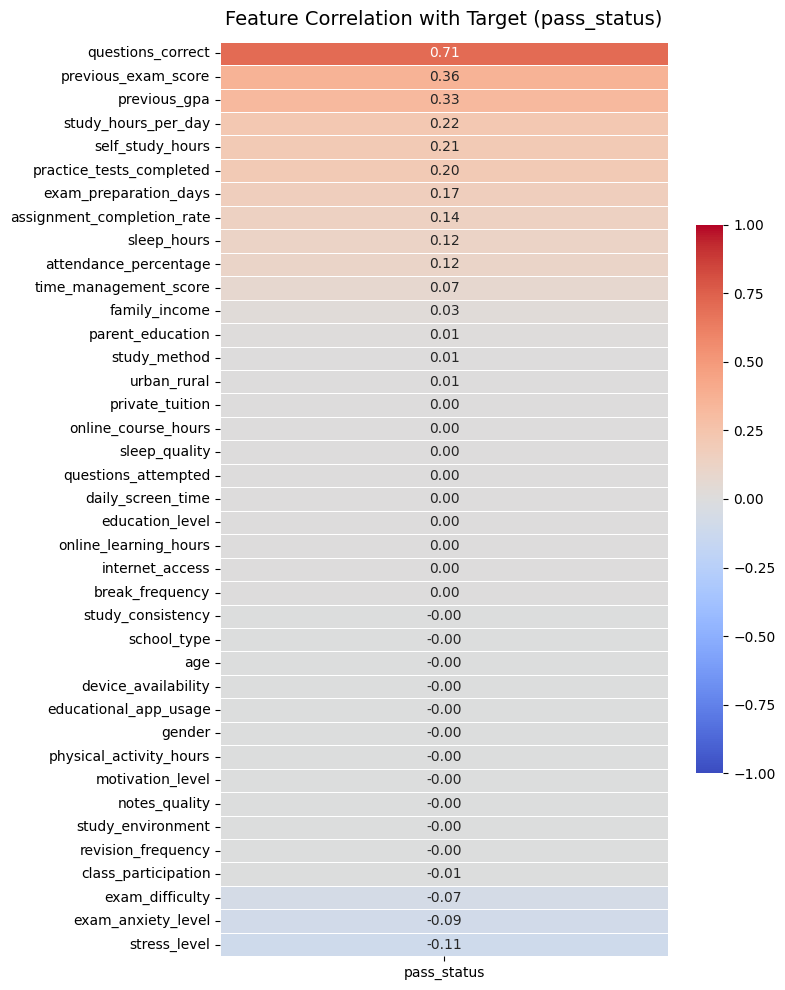

In [ ]:
corr_with_target = X_train_clean.copy()
corr_with_target['pass_status'] = y_train_encoded

target_corr = corr_with_target.corr()[['pass_status']].drop('pass_status').sort_values(by='pass_status', ascending=False)

plt.figure(figsize=(8, 10))
sns.heatmap(
    target_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.6}
)
plt.title("Feature Correlation with Target (pass_status)", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

In [ ]:
features_selected = ["study_hours_per_day", "previous_exam_score", "exam_difficulty"]

X_train_selected = X_train_clean[features_selected]
X_test_selected = X_test_clean[features_selected]

print("Selected training set shape:", X_train_selected.shape)
X_train_selected.head()

Selected training set shape: (80000, 3)


,study_hours_per_day,previous_exam_score,exam_difficulty
56663,2.81,76.61,0.0
73742,2.35,56.39,2.0
79971,2.19,65.96,1.0
86394,3.26,90.85,1.0
27572,2.56,73.33,0.0


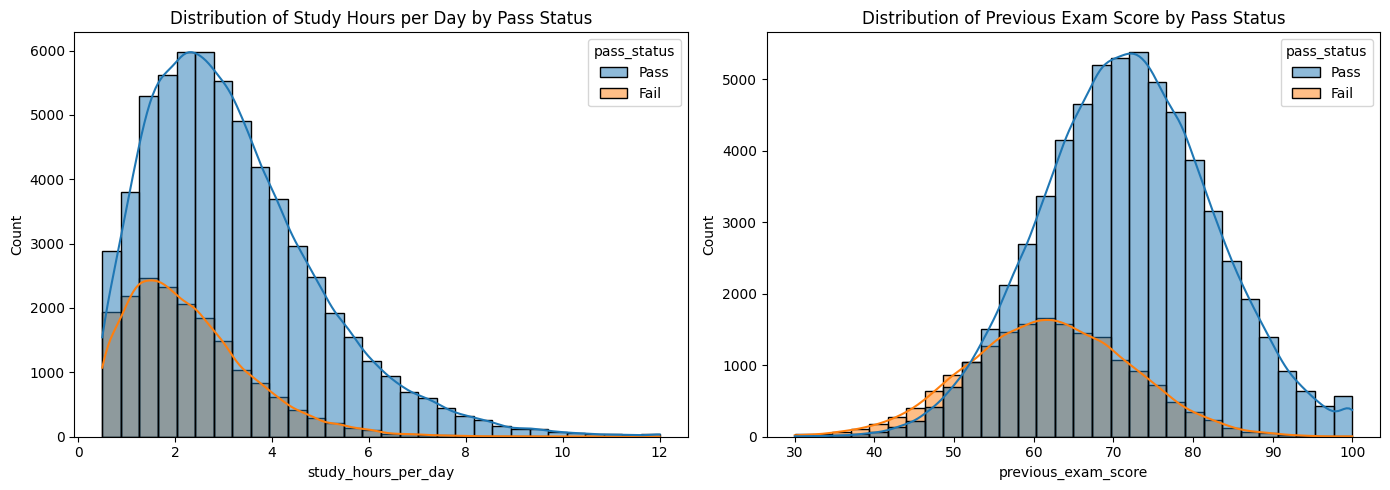

In [ ]:
plot_df = X_train_selected.copy()
plot_df['pass_status'] = y_train

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=plot_df, x='study_hours_per_day', hue='pass_status', kde=True, bins=30, ax=axes[0])
axes[0].set_title('Distribution of Study Hours per Day by Pass Status')

sns.histplot(data=plot_df, x='previous_exam_score', hue='pass_status', kde=True, bins=30, ax=axes[1])
axes[1].set_title('Distribution of Previous Exam Score by Pass Status')

plt.tight_layout()
plt.show()

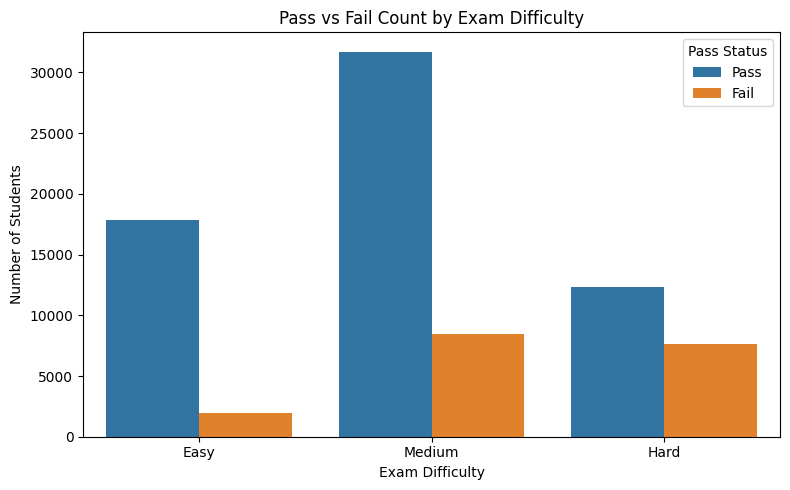

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=X_train, x='exam_difficulty', hue=y_train, order=['Easy', 'Medium', 'Hard'])

plt.title('Pass vs Fail Count by Exam Difficulty')
plt.xlabel('Exam Difficulty')
plt.ylabel('Number of Students')
plt.legend(title='Pass Status')
plt.tight_layout()
plt.show()

#Conclusion
From the three graphs, we can see that previous exam score and daily study hours are the strongest positive drivers of passing, as students in the Pass group consistently show higher medians and right-shifted distributions compared to those who Fail. Conversely, exam difficulty shows an inverse relationship with success—while the majority of students pass across all tiers, the proportion of failures increases noticeably as the exam moves from Easy to Hard. Overall, strong prior academic performance combined with consistent daily study habits significantly boosts a student's likelihood of passing, even when facing higher exam difficulty.
